# Early supermassive black holes: evidence and growth constraints

This reproducible notebook evaluates what early SMBH observations do—and do not—say about seed formation. It separates **direct dynamical mass**, **broad-line virial mass**, **luminosity/Eddington-inferred mass**, and **AGN candidate** classifications. Literature values below are reported estimates, not recalibrated measurements. Growth calculations are illustrative constant-parameter scenarios, not reconstructions of observed histories.

Source links: Planck 2018 cosmology [Planck Collaboration (2020)](https://doi.org/10.1051/0004-6361/201833910); [CEERS_1019](https://arxiv.org/abs/2303.08918); [GN-z11](https://doi.org/10.1038/s41586-024-07052-5); [UHZ1](https://arxiv.org/abs/2308.02654); [J0313−1806](https://doi.org/10.3847/2041-8213/abd8c6); [Abell 2744-QSO1 direct dynamics](https://doi.org/10.1038/s41586-026-10579-4).


## 1. Cosmology, cosmic age, and observation ledger

Use Astropy `Planck18` flat $\Lambda$CDM: $H_0=67.66\,\mathrm{km\,s^{-1}\,Mpc^{-1}}$, $\Omega_m=0.30966$, $\Omega_\Lambda=0.68885$, $T_{\rm CMB}=2.7255\,\mathrm{K}$, and $N_{\rm eff}=3.046$ (Planck Collaboration 2020; Astropy `Planck18`). Radiation and neutrinos mean $\Omega_\Lambda\ne1-\Omega_m$ exactly. Reported observation ages are source-paper values when available; model ages below use this specified cosmology.

The ledger is intentionally small and heterogeneous; mass methods are not interchangeable. “Direct dynamical” here means resolved gas kinematic modelling, not a virial line-width calibration. Values classified as candidates/inferred remain model dependent. Errors reproduce the quoted paper's form and are not homogenized.


In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.cosmology import Planck18
from scipy.optimize import brentq
from sympy import symbols, Eq, solve, simplify, diff, exp, log

cosmo = Planck18
print(f'Planck18: H0={cosmo.H0:.1f}, Om0={cosmo.Om0:.3f}, Ode0={cosmo.Ode0:.3f}; age today={cosmo.age(0).to_value(u.Gyr):.3f} Gyr')
age_to_redshift = lambda age_gyr: brentq(lambda z: cosmo.age(z).to_value(u.Gyr)-age_gyr, 0.0, 100.0)
print(f'Age-redshift inversion cross-check at z=10: z(age)={age_to_redshift(cosmo.age(10).to_value(u.Gyr)):.6f}')

observations = pd.DataFrame([
 {'object':'Abell 2744-QSO1','z':7.04,'mass_msun':10**7.7,'mass_note':'log10(M/Msun)=7.7 ± 0.3 (inclination-corrected MOKA3D); simpler fit 6.75 ± 0.15 is a lower bound','class':'Resolved gas dynamics; direct kinematic estimate','luminosity_or_rate':'Eddington ratio ≈0.02','caveat':'Inclination/deprojection and model/systematic uncertainty; paper discusses nuclear cluster and primordial-BH alternatives','source':'https://doi.org/10.1038/s41586-026-10579-4'},
 {'object':'GN-z11','z':10.603,'mass_msun':10**6.2,'mass_note':'log10(MBH/Msun)=6.2 ± 0.3 (local virial relations); alternative Eddington-based estimate ~1e7','class':'AGN supported by JWST/NIRSpec; virial mass, not direct dynamical','luminosity_or_rate':'Lbol≈1e45 erg/s; about 5× Eddington with factor ~2 uncertainty','caveat':'Local virial calibration may not hold at z>10; line decomposition and AGN/host contributions matter','source':'https://doi.org/10.1038/s41586-024-07052-5'},
 {'object':'CEERS_1019','z':8.679,'mass_msun':10**6.95,'mass_note':'log10(MBH/Msun)=6.95 ± 0.37','class':'Broad-Hβ virial estimate; spectroscopic AGN evidence','luminosity_or_rate':'L/LEdd=1.2 ± 0.5','caveat':'Single-epoch broad-line scaling; intrinsic scatter and potential systematics','source':'https://arxiv.org/abs/2303.08918'},
 {'object':'UHZ1','z':10.1,'mass_msun':4e7,'mass_note':'~4e7 Msun inferred from bolometric luminosity assuming Eddington; X-ray obscuration-dependent estimate is weakly constrained','class':'Chandra+JWST X-ray AGN; mass is luminosity/Eddington inferred, not secure dynamical','luminosity_or_rate':'Lbol~5e45 erg/s; Compton-thick candidate','caveat':'Weakly constrained column density, lensing magnification and bolometric correction; not direct mass','source':'https://arxiv.org/abs/2308.02654'},
 {'object':'J0313−1806','z':7.6423,'mass_msun':1.6e9,'mass_note':'(1.6 ± 0.4)×10^9 Msun; MgII virial estimate','class':'Luminous spectroscopically confirmed quasar; virial mass','luminosity_or_rate':'Lbol=(1.4 ± 0.1)×10^47 erg/s; Lbol/LEdd=0.67 ± 0.14','caveat':'Virial calibration; BAL/outflow and line shifts; rarity and flux selection bias the observed sample','source':'https://doi.org/10.3847/2041-8213/abd8c6'}
])


Planck18: H0=67.7 km / (Mpc s), Om0=0.310, Ode0=0.689; age today=13.787 Gyr
Age-redshift inversion cross-check at z=10: z(age)=10.000000


,object,z,age_Gyr_Planck18,mass_note,class,luminosity_or_rate,caveat,source
0,Abell 2744-QSO1,7.0400,0.754907,log10(M/Msun)=7.7 ± 0.3 (inclination-corrected...,Resolved gas dynamics; direct kinematic estimate,Eddington ratio ≈0.02,Inclination/deprojection and model/systematic ...,https://doi.org/10.1038/s41586-026-10579-4
1,GN-z11,10.6030,0.435070,log10(MBH/Msun)=6.2 ± 0.3 (local virial relati...,"AGN supported by JWST/NIRSpec; virial mass, no...",Lbol≈1e45 erg/s; about 5× Eddington with facto...,Local virial calibration may not hold at z>10;...,https://doi.org/10.1038/s41586-024-07052-5
2,CEERS_1019,8.6790,0.571348,log10(MBH/Msun)=6.95 ± 0.37,Broad-Hβ virial estimate; spectroscopic AGN ev...,L/LEdd=1.2 ± 0.5,Single-epoch broad-line scaling; intrinsic sca...,https://arxiv.org/abs/2303.08918
3,UHZ1,10.1000,0.465045,~4e7 Msun inferred from bolometric luminosity ...,Chandra+JWST X-ray AGN; mass is luminosity/Edd...,Lbol~5e45 erg/s; Compton-thick candidate,"Weakly constrained column density, lensing mag...",https://arxiv.org/abs/2308.02654
4,J0313−1806,7.6423,0.677325,(1.6 ± 0.4)×10^9 Msun; MgII virial estimate,Luminous spectroscopically confirmed quasar; v...,Lbol=(1.4 ± 0.1)×10^47 erg/s; Lbol/LEdd=0.67 ±...,Virial calibration; BAL/outflow and line shift...,https://doi.org/10.3847/2041-8213/abd8c6


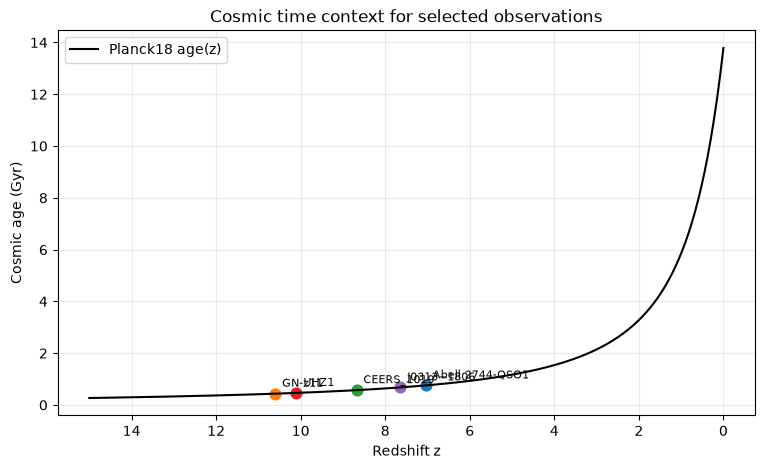

In [2]:
observations['age_Gyr_Planck18'] = [cosmo.age(z).to_value(u.Gyr) for z in observations.z]
display(observations[['object','z','age_Gyr_Planck18','mass_note','class','luminosity_or_rate','caveat','source']])

fig, ax = plt.subplots(figsize=(9,5))
zgrid=np.linspace(0,15,400); age=cosmo.age(zgrid).to_value(u.Gyr)
ax.plot(zgrid,age,color='black',label='Planck18 age(z)')
for row in observations.itertuples():
 ax.scatter(row.z,row.age_Gyr_Planck18,s=60); ax.annotate(row.object,(row.z,row.age_Gyr_Planck18),xytext=(5,5),textcoords='offset points',fontsize=8)
ax.set(xlabel='Redshift z',ylabel='Cosmic age (Gyr)',title='Cosmic time context for selected observations'); ax.invert_xaxis(); ax.grid(alpha=.25); ax.legend(); plt.show()


## 2. Eddington limit and exponential growth (algebra shown)

For ionized hydrogen, balance outward radiation force on an electron–proton pair against gravity on the proton, assuming spherical isotropic radiation and Thomson opacity. The radiation force is $F_{\rm rad}=\sigma_T L/(4\pi r^2c)$ and gravity is $F_g=GMm_p/r^2$. Equating and cancelling $r^{-2}$ gives $L_{\rm Edd}=4\pi GMm_pc/\sigma_T$. With standard constants this is approximately $1.26\times10^{38}(M/M_\odot)\,\mathrm{erg\,s^{-1}}$. Composition changes opacity and the coefficient.

Let radiative efficiency be $\epsilon=L/(\dot M_{\rm in}c^2)$ and let $\lambda=L/L_{\rm Edd}$. Only $1-\epsilon$ of inflowing rest mass is retained, so $dM/dt=(1-\epsilon)\dot M_{\rm in}=(1-\epsilon)L/(\epsilon c^2)$. Substituting $L=\lambda L_{\rm Edd}$ and $L_{\rm Edd}=4\pi GMm_pc/\sigma_T$ yields $dM/dt=[(1-\epsilon)/\epsilon]\lambda(4\pi Gm_p/\sigma_Tc)M$. If active for fraction $f_{\rm duty}$ of elapsed time and parameters are constant, replace $\lambda$ by $f_{\rm duty}\lambda$. Thus $dM/M=dt/t_{\rm ef}$; integrating from $(M_0,t_0)$ to $(M,t)$ gives $\ln(M/M_0)=(t-t_0)/t_{\rm ef}$ and $M=M_0\exp[(t-t_0)/t_{\rm ef}]$.

The e-folding time is $t_{\rm ef}=\frac{\epsilon}{1-\epsilon}\frac{\sigma_Tc}{4\pi Gm_p}\frac{1}{f_{\rm duty}\lambda}=0.450\,\mathrm{Gyr}\frac{\epsilon}{1-\epsilon}(f_{\rm duty}\lambda)^{-1}$. At $\epsilon=0.1$, $f_{\rm duty}=\lambda=1$, this is 50.0 Myr (often rounded to 45–50 Myr depending on constants/convention). These equations describe idealized radiatively efficient accretion; mergers, variable duty cycles, supercritical flows, changing spin/efficiency, and feedback are omitted.


In [3]:
# Symbolic verification of the algebraic growth solution and inverse seed constraint.
M, M0, t, t0, tef, eps, lam, duty, G, mp, c, sig = symbols('M M0 t t0 tef eps lam duty G mp c sig', positive=True)
growth = Eq(M, M0*exp((t-t0)/tef))
print('d/dt growth / growth =', simplify(diff(M0*exp((t-t0)/tef),t)/(M0*exp((t-t0)/tef))))
print('inverse seed mass =', solve(growth,M0)[0])
LEdd = 4*symbols('pi')*G*M*mp*c/sig
print('Eddington expression:', LEdd)
print('efficiency factor retained-mass rate: (1-eps)/eps =', simplify((1-eps)/eps))

# Astropy constants provide a unit-checked numerical calibration.
from astropy.constants import G as G_ast, m_p, c as c_ast, sigma_T, M_sun
t0_sal = (sigma_T*c_ast/(4*np.pi*G_ast*m_p)).to(u.Gyr)
def salpeter_myr(epsilon=0.1, edd_ratio=1.0, duty=1.0):
 return (t0_sal.to_value(u.Gyr)*epsilon/(1-epsilon)/(edd_ratio*duty))*1e3
print(f'Composition: pure ionized H; L_Edd/Msun={(4*np.pi*G_ast*M_sun*m_p*c_ast/sigma_T).to_value(u.erg/u.s):.3e} erg/s')
print(f'Salpeter e-fold at epsilon=.1, lambda=duty=1: {salpeter_myr():.2f} Myr')


d/dt growth / growth = 1/tef
inverse seed mass = M*exp((-t + t0)/tef)
Eddington expression: 4*G*M*c*mp*pi/sig
efficiency factor retained-mass rate: (1-eps)/eps = (1 - eps)/eps
Composition: pure ionized H; L_Edd/Msun=1.257e+38 erg/s
Salpeter e-fold at epsilon=.1, lambda=duty=1: 50.05 Myr


## 3. Formation-to-observation growth scenarios

For a target mass $M_{\rm obs}$ reached from seed $M_{\rm seed}$ between formation redshift $z_f$ and observed redshift $z_o$, the available time is $\Delta t=t(z_o)-t(z_f)$, using Planck18 cosmic ages. Rearranging the integrated growth law gives required seed mass $M_{\rm seed,req}=M_{\rm obs}\exp[-\Delta t/t_{\rm ef}]$. Feasibility is conditional: if this required seed exceeds an assumed seed, constant-parameter growth is insufficient; this is not proof against that channel if earlier formation, super-Eddington phases, mergers, or non-constant histories are allowed.

We span explicit assumptions: seed masses 10, 100, 10^3, 10^4, 10^5, 10^6 solar masses; formation redshifts 15, 20, 25, 30; efficiencies 0.057, 0.1, 0.2, 0.3; duty cycles 0.1, 0.3, 0.7, 1; Eddington ratios 0.3, 1, 2, 5. The endpoints are illustrative, not priors nor claimed measurements. Constant $f_{\rm duty}$ and $\lambda$ denote effective time averages; constant $\epsilon$ is a major simplification.


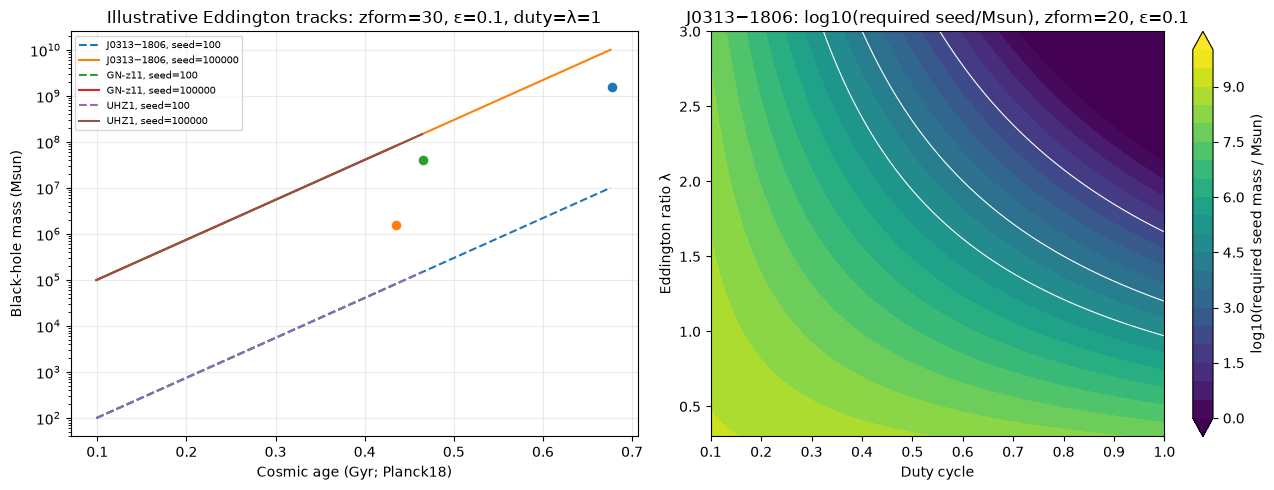

,required_seed_min,required_seed_max
object,,
CEERS_1019,710.0,20918.0
GN-z11,1922.0,56616.0
J0313−1806,15345.0,452004.0
UHZ1,26652.0,785081.0


In [4]:
seed_grid=np.array([10,100,1e3,1e4,1e5,1e6])
formation_z=[15,20,25,30]
eps_grid=[.057,.1,.2,.3]; duty_grid=[.1,.3,.7,1.]; lambda_grid=[.3,1.,2.,5.]
targets=observations.set_index('object').loc[['J0313−1806','GN-z11','UHZ1','CEERS_1019']].reset_index()
def required_seed(target, zobs, zform, epsilon, duty, edd_ratio):
 dt=(cosmo.age(zobs)-cosmo.age(zform)).to_value(u.Gyr)
 if dt<=0: return np.nan
 te=(t0_sal.to_value(u.Gyr)*epsilon/(1-epsilon)/(duty*edd_ratio))
 return target*np.exp(-dt/te)

# Literature-inspired reference tracks at explicitly stated fixed parameters.
fig, axes=plt.subplots(1,2,figsize=(13,5))
ztrack=np.linspace(30,5,500); ages=cosmo.age(ztrack).to_value(u.Gyr)
for obj,zobs,target in [('J0313−1806',7.6423,1.6e9),('GN-z11',10.603,10**6.2),('UHZ1',10.1,4e7)]:
 for mseed, ls in [(100,'--'),(1e5,'-')]:
  times=ages[ages<=cosmo.age(zobs).to_value(u.Gyr)]
  mass=mseed*np.exp((times-cosmo.age(30).to_value(u.Gyr))/(salpeter_myr(.1)/1000))
  axes[0].plot(times,mass,ls,label=f'{obj}, seed={mseed:g}')
 axes[0].scatter(cosmo.age(zobs).to_value(u.Gyr),target,s=35)
axes[0].set(yscale='log',xlabel='Cosmic age (Gyr; Planck18)',ylabel='Black-hole mass (Msun)',title='Illustrative Eddington tracks: zform=30, ε=0.1, duty=λ=1'); axes[0].grid(alpha=.25); axes[0].legend(fontsize=7)

# Required seed as a function of duty cycle and Eddington ratio at epsilon=0.1.
zform=20; eps0=.1
D,L=np.meshgrid(np.linspace(.1,1,100),np.linspace(.3,3,100))
for ax,(obj,zobs,target) in zip(axes[1:], [('J0313−1806',7.6423,1.6e9)]):
 dt=(cosmo.age(zobs)-cosmo.age(zform)).to_value(u.Gyr)
 te=t0_sal.to_value(u.Gyr)*eps0/(1-eps0)/(D*L)
 req=target*np.exp(-dt/te)
 im=ax.contourf(D,L,np.log10(req),levels=np.arange(0,10.1,.5),cmap='viridis',extend='both')
 ax.contour(D,L,np.log10(req),levels=[2,4,5],colors='white',linewidths=.8)
 ax.set(xlabel='Duty cycle',ylabel='Eddington ratio λ',title='J0313−1806: log10(required seed/Msun), zform=20, ε=0.1')
 fig.colorbar(im,ax=ax,label='log10(required seed mass / Msun)')
fig.tight_layout(); plt.show()

grid=[]
for row in targets.itertuples():
 for zf in formation_z:
  for e in eps_grid:
   for d in duty_grid:
    for l in lambda_grid:
     req=required_seed(row.mass_msun,row.z,zf,e,d,l)
     grid.append({'object':row.object,'zform':zf,'epsilon':e,'duty':d,'lambda':l,'required_seed_Msun':req})
scenario=pd.DataFrame(grid)
display(scenario[(scenario.epsilon == 0.1) & (scenario.duty == 1.0) & (scenario['lambda'] == 1.0)].groupby('object').agg(required_seed_min=('required_seed_Msun','min'), required_seed_max=('required_seed_Msun','max')).round(0))


## 4. Seed-feasibility diagnostic and observational uncertainty

The following heat map evaluates the **minimum required seed mass** for the luminosity-inferred UHZ1 mass under fixed $z_f=20$, $\epsilon=0.1$, and a grid of $f_{\rm duty}$ and $\lambda$. It overlays illustrative seed scales (10–100 solar masses for stellar remnants; 10^4–10^5 solar masses for direct-collapse scenarios) as reference bands, not categorical boundaries. A cell below a seed threshold says only that the simplified mass budget can reach the target. It does not establish that the seed exists, has the required gas supply, or can maintain the assumed history.

The separate diagnostic compares the accretion luminosities of sources with both published mass and luminosity/rate information to $L_{\rm Edd}=1.26\times10^{38} M/M_\odot$; for mass estimates derived from luminosity/Eddington the ratio is circular by construction. Virial masses use scaling relations and their systematics; direct kinematic MOKA3D estimates involve inclination/deprojection and model choices. Errors in quoted masses should not be treated as independent Gaussian draws across methods.


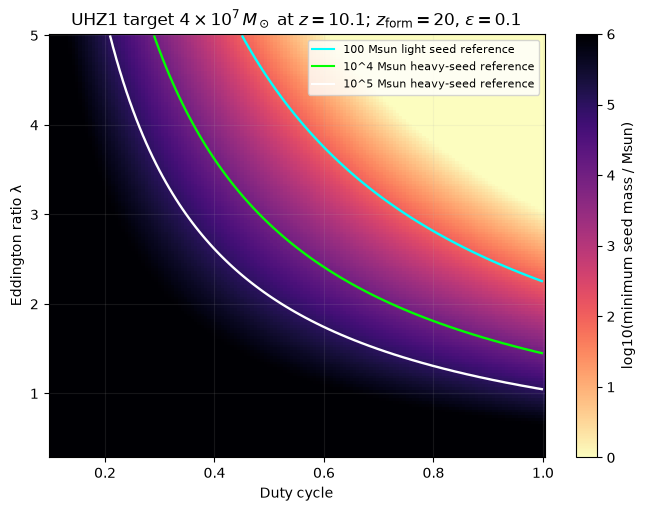

In [5]:
# UHZ1 seed feasibility map with explicit reference seed bands.
zobs=10.1; target=4e7; zform=20; eps=.1
D,L=np.meshgrid(np.linspace(.1,1,150),np.linspace(.3,5,150))
dt=(cosmo.age(zobs)-cosmo.age(zform)).to_value(u.Gyr)
te=t0_sal.to_value(u.Gyr)*eps/(1-eps)/(D*L)
required=target*np.exp(-dt/te)
fig,ax=plt.subplots(figsize=(8,5.5))
im=ax.pcolormesh(D,L,np.log10(required),shading='auto',cmap='magma_r',vmin=0,vmax=6)
for seed,color,label in [(100,'cyan','100 Msun light seed reference'),(1e4,'lime','10^4 Msun heavy-seed reference'),(1e5,'white','10^5 Msun heavy-seed reference')]:
 ax.contour(D,L,required,levels=[seed],colors=[color],linewidths=1.7)
 ax.plot([],[],color=color,label=label)
ax.set(xlabel='Duty cycle',ylabel='Eddington ratio λ',title='UHZ1 target $4\\times10^7\\,M_\\odot$ at $z=10.1$; $z_{\\rm form}=20$, $\\epsilon=0.1$')
fig.colorbar(im,ax=ax,label='log10(minimum seed mass / Msun)'); ax.legend(fontsize=8); ax.grid(alpha=.12); plt.show()

# Observational mass/luminosity diagnostic, using literature-reported values.
diagnostic=pd.DataFrame([
 {'object':'J0313−1806','mass':1.6e9,'Lbol_erg_s':1.4e47,'reported_ratio':.67,'method':'MgII virial'},
 {'object':'GN-z11','mass':10**6.2,'Lbol_erg_s':1e45,'reported_ratio':5.,'method':'local virial (reported approximate)'},
 {'object':'CEERS_1019','mass':10**6.95,'Lbol_erg_s':1.2*1.26e38*10**6.95,'reported_ratio':1.2,'method':'broad-Hβ virial; luminosity reconstructed from reported λEdd'}])

,object,method,reported_ratio,implied_L_over_Ledd
0,J0313−1806,MgII virial,0.67,0.694444
1,GN-z11,local virial (reported approximate),5.00,5.007598
2,CEERS_1019,broad-Hβ virial; luminosity reconstructed from...,1.20,1.200000


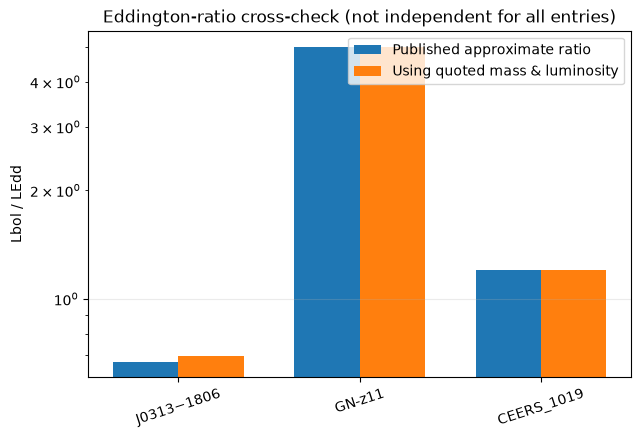

In [6]:
diagnostic['Ledd_erg_s']=1.26e38*diagnostic.mass
diagnostic['implied_L_over_Ledd']=diagnostic.Lbol_erg_s/diagnostic.Ledd_erg_s
display(diagnostic[['object','method','reported_ratio','implied_L_over_Ledd']])
fig,ax=plt.subplots(figsize=(7,4.5)); x=np.arange(len(diagnostic)); w=.36
ax.bar(x-w/2,diagnostic.reported_ratio,w,label='Published approximate ratio')
ax.bar(x+w/2,diagnostic.implied_L_over_Ledd,w,label='Using quoted mass & luminosity')
ax.set_xticks(x,diagnostic.object,rotation=18); ax.set_yscale('log'); ax.set_ylabel('Lbol / LEdd'); ax.set_title('Eddington-ratio cross-check (not independent for all entries)'); ax.grid(axis='y',alpha=.25); ax.legend(); plt.show()


## 5. Interpretation, uncertainty, and references

The selected observations cover distinct regimes: luminous z≈7.6 quasars with billion-solar-mass **virial** estimates; JWST spectroscopic AGN with million-solar-mass virial estimates; the heavily obscured X-ray UHZ1 AGN with a strongly model-dependent luminosity-based mass; and Abell 2744-QSO1, for which spatially resolved gas kinematics provide a dynamical mass estimate, itself dependent on inclination/model assumptions. These are not a uniformly selected sample. Quasar discovery is luminosity/flux limited, JWST targets are survey-selected, lensed systems depend on magnification models, X-ray detections favor active phases, and obscuration plus line-detection thresholds shape all samples. The notebook does not infer population rates.

The simple growth model exposes degeneracies: the required mass depends exponentially on available time and on the product of duty cycle and Eddington ratio, while efficiency changes the e-folding time. An early heavy seed can permit ordinary Eddington growth; a light stellar-remnant seed may require high effective accretion, long duty cycle, earlier formation, mergers, or supercritical episodes. Multiple combinations can reach the same endpoint. Uncertain virial calibration at very high redshift, transient AGN variability, host contamination, obscuration corrections, lensing, unknown spin-dependent efficiency, and cosmic variance all widen the possibilities. Current evidence therefore does **not** uniquely identify Population III remnants, direct-collapse seeds, nuclear-cluster pathways, primordial black holes, or any other single channel.

### References (measurement and cosmology sources)
1. Planck Collaboration (2020), *Planck 2018 results. VI. Cosmological parameters*, A&A 641, A6. [DOI](https://doi.org/10.1051/0004-6361/201833910).
2. Larson et al. (2023), *A CEERS Discovery of an Accreting Supermassive Black Hole 570 Myr after the Big Bang*, ApJL 953, L29. [arXiv:2303.08918](https://arxiv.org/abs/2303.08918), [DOI:10.3847/2041-8213/ace619](https://doi.org/10.3847/2041-8213/ace619).
3. Maiolino et al. (2024), *A small and vigorous black hole in the early Universe*, Nature 627, 59–63. [DOI:10.1038/s41586-024-07052-5](https://doi.org/10.1038/s41586-024-07052-5).
4. Natarajan et al. (2023), *First Detection of an Over-Massive Black Hole Galaxy UHZ1*, ApJL 958, L20. [arXiv:2308.02654](https://arxiv.org/abs/2308.02654).
5. Wang et al. (2021), *A Luminous Quasar at Redshift 7.642*, ApJL 907, L1. [DOI:10.3847/2041-8213/abd8c6](https://doi.org/10.3847/2041-8213/abd8c6), [arXiv:2101.03179](https://arxiv.org/abs/2101.03179).
6. Juodžbalis et al. (2026), direct dynamical black-hole mass in Abell 2744-QSO1, Nature 653, 1017–1021. [DOI:10.1038/s41586-026-10579-4](https://doi.org/10.1038/s41586-026-10579-4). The inclination-unconstrained simple rotation result and inclination-corrected MOKA3D result differ substantially; neither should be conflated with a virial measurement.

Notebook calculations are reproducible with Astropy, NumPy, pandas, SciPy, SymPy, and matplotlib. No external catalogs or downloaded data are required.